In [15]:
import matplotlib.pyplot as plt
import pandas as pd
import pylab as pl
import numpy as np

In [16]:
import numpy as np


In [17]:
df=pd.read_csv("FuelConsumption.csv")

df.head()

,MODELYEAR,MAKE,MODEL,VEHICLECLASS,ENGINESIZE,CYLINDERS,TRANSMISSION,FUELTYPE,FUELCONSUMPTION_CITY,FUELCONSUMPTION_HWY,FUELCONSUMPTION_COMB,FUELCONSUMPTION_COMB_MPG,CO2EMISSIONS
0,2014,ACURA,ILX,COMPACT,2.0,4,AS5,Z,9.9,6.7,8.5,33,196
1,2014,ACURA,ILX,COMPACT,2.4,4,M6,Z,11.2,7.7,9.6,29,221
2,2014,ACURA,ILX HYBRID,COMPACT,1.5,4,AV7,Z,6.0,5.8,5.9,48,136
3,2014,ACURA,MDX 4WD,SUV - SMALL,3.5,6,AS6,Z,12.7,9.1,11.1,25,255
4,2014,ACURA,RDX AWD,SUV - SMALL,3.5,6,AS6,Z,12.1,8.7,10.6,27,244


In [18]:
df.describe()

,MODELYEAR,ENGINESIZE,CYLINDERS,FUELCONSUMPTION_CITY,FUELCONSUMPTION_HWY,FUELCONSUMPTION_COMB,FUELCONSUMPTION_COMB_MPG,CO2EMISSIONS
count,1067.0,1067.000000,1067.000000,1067.000000,1067.000000,1067.000000,1067.000000,1067.000000
mean,2014.0,3.346298,5.794752,13.296532,9.474602,11.580881,26.441425,256.228679
std,0.0,1.415895,1.797447,4.101253,2.794510,3.485595,7.468702,63.372304
min,2014.0,1.000000,3.000000,4.600000,4.900000,4.700000,11.000000,108.000000
25%,2014.0,2.000000,4.000000,10.250000,7.500000,9.000000,21.000000,207.000000
50%,2014.0,3.400000,6.000000,12.600000,8.800000,10.900000,26.000000,251.000000
75%,2014.0,4.300000,8.000000,15.550000,10.850000,13.350000,31.000000,294.000000
max,2014.0,8.400000,12.000000,30.200000,20.500000,25.800000,60.000000,488.000000


In [19]:
a=df[['ENGINESIZE','FUELCONSUMPTION_COMB', 'CYLINDERS', 'CO2EMISSIONS']]
a.head(9)

,ENGINESIZE,FUELCONSUMPTION_COMB,CYLINDERS,CO2EMISSIONS
0,2.0,8.5,4,196
1,2.4,9.6,4,221
2,1.5,5.9,4,136
3,3.5,11.1,6,255
4,3.5,10.6,6,244
5,3.5,10.0,6,230
6,3.5,10.1,6,232
7,3.7,11.1,6,255
8,3.7,11.6,6,267


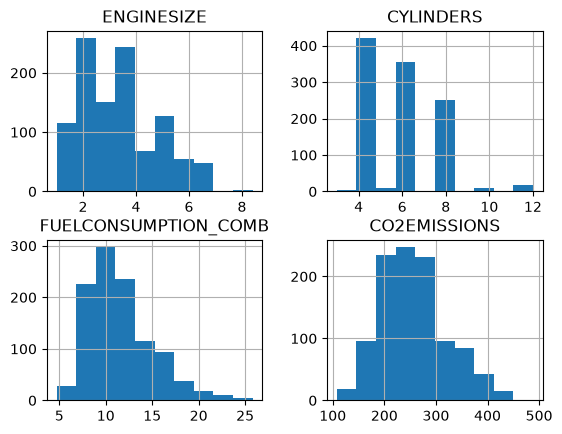

In [20]:
b=a[['ENGINESIZE','CYLINDERS','FUELCONSUMPTION_COMB','CO2EMISSIONS']]                    #اعداد داخل کادرAهستند
b.hist()
plt.show()

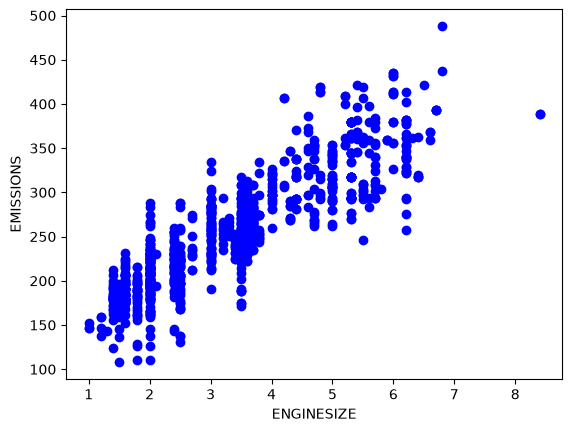

In [21]:
plt.scatter(a.ENGINESIZE, a.CO2EMISSIONS, color='blue')
plt.xlabel("ENGINESIZE")
plt.ylabel("EMISSIONS")
plt.show()

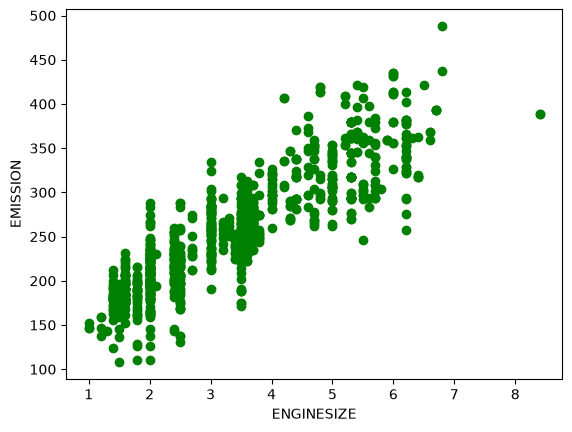

In [22]:
plt.scatter(a.ENGINESIZE, a.CO2EMISSIONS, color='green')
plt.xlabel("ENGINESIZE")
plt.ylabel("EMISSION")
plt.show()

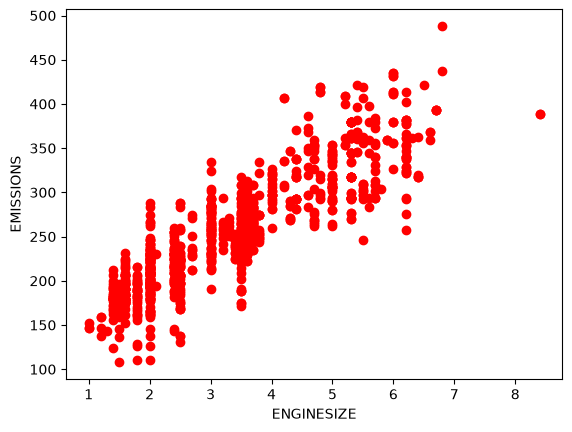

In [23]:
plt.scatter(a.ENGINESIZE, a.CO2EMISSIONS, color='red')
plt.xlabel("ENGINESIZE")
plt.ylabel("EMISSIONS")
plt.show()

In [24]:
msk=np.random.rand(len(a)) > 0.8
train = a[msk]
test = a[~msk]

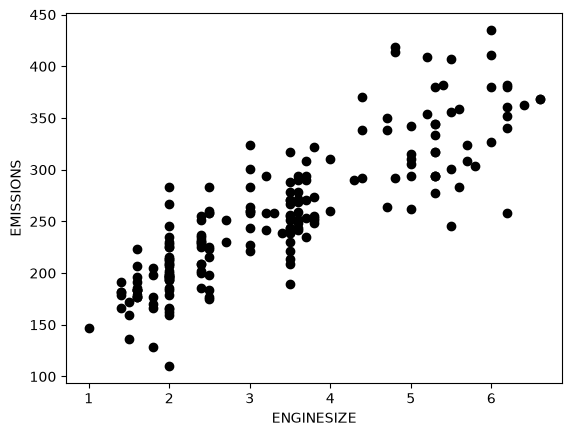

In [25]:
plt.scatter(train.ENGINESIZE, train.CO2EMISSIONS, color='black') 
plt.xlabel("ENGINESIZE")                #انتخاب میکنیم ک از کدام متغیرها استفاده کنیم
plt.ylabel("EMISSIONS")
plt.show()

In [26]:
from sklearn import linear_model
regr=linear_model.LinearRegression()
train_x = np.asanyarray(train[['ENGINESIZE']])
train_y = np.asanyarray(train[['CO2EMISSIONS']])
regr.fit(train_x ,  train_y)
print('coeffication:' , regr.coef_)
print('intercept:' , regr.intercept_)

coeffication: [[38.58470088]]
intercept: [125.65317199]


Text(0, 0.5, 'EMISSION')

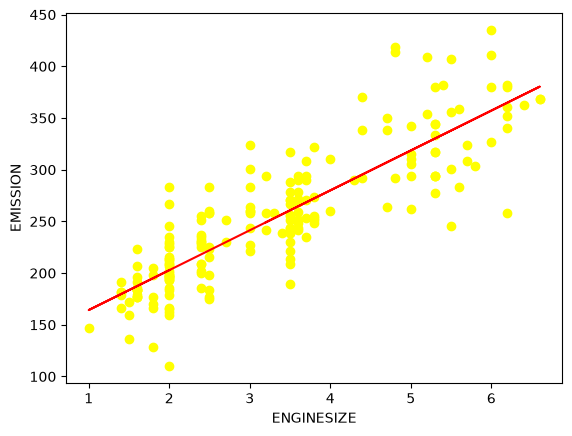

In [27]:
plt.scatter(train.ENGINESIZE, train.CO2EMISSIONS,color="yellow")
plt.plot(train_x , regr.coef_[0][0]*train_x + regr.intercept_[0],'-r')
plt.xlabel("ENGINESIZE")
plt.ylabel("EMISSION")

In [28]:
from sklearn.metrics import r2_score

test_x = np.asanyarray(df[['ENGINESIZE']])
test_y = np.asanyarray(df[['CO2EMISSIONS']])
test_y_ = regr.predict(test_x)

print("Mean absolute error: %.2f" % np.mean(np.absolute(test_y_ - test_y)))
print("Residual sum of squares (MSE): %.2f" % np.mean((test_y_ - test_y) ** 2))
print("R2-score: %.2f" % r2_score(test_y , test_y_) )

Mean absolute error: 23.30
Residual sum of squares (MSE): 949.03
R2-score: 0.76
